In [1]:
import pandas as pd

In [2]:
# Load the necessary tables, rq1 and rq2 mechanism tables etc

# Look at relationships between patterns that appear in initial findings vs workflows in the same dir
# Look at if the introduced findings follow the patterns observed in the initial findings
# Look at if the distance between introduced findings and initial findings follows any patterns

In [3]:
from pathlib import Path

import pandas as pd

paper_dir = Path(
    r"C:\Users\mekae\Desktop\CS\Masters\Workflow_Research\Experiments\Paper_A"
)
outputs_dir = Path(
    r"E:\!My Files\CS\Grammar\WorkflowResearch_Generated\paper_a_outputs"
)

full_run_dir = outputs_dir / "full_run"
base_commits_dir = outputs_dir / "base_workflows" / "commits"

In [4]:
# One row per workflow-file change, including changes with zero findings.
pairs_df = pd.read_parquet(
    full_run_dir / "pairs_summary.parquet",
    columns=[
        "pair_id", "source", "repo", "commit_or_pr", "base_sha",
        "change_type", "conversion_status", "scan_status", "side_scan_counts",
    ],
    filters=[("source", "==", "aidev_v5")],
)

# One row per scanner finding, with status introduced, persisted, or fixed.
findings_df = pd.read_parquet(
    full_run_dir / "findings.parquet",
    columns=["pair_id", "oracle", "rule_id", "status"],
    filters=[
        ("source", "==", "aidev_v5"),
        ("oracle", "in", ["zizmor", "actionlint"]),
    ],
)

# File paths let us identify the workflow being edited in the base snapshot.
paths_df = pd.read_parquet(
    outputs_dir / "pairs.parquet",
    columns=["pair_id", "before_path", "after_path", "before_exists", "after_exists"],
    filters=[("source", "==", "aidev_v5")],
)

# Workflow size and the gh-aw generation marker for later checks.
workflow_features_df = pd.read_parquet(
    paper_dir / "Final Results" / "workflow_features.parquet"
)

# Rule-level audit from our earlier measurement check.
rule_profiles_df = pd.read_parquet(
    paper_dir / "RQ3 Measurement Check" / "rule_reporting_profiles.parquet"
)

print(f"Workflow changes: {len(pairs_df):,}")
print(f"Scanner findings: {len(findings_df):,}")

Workflow changes: 248,110
Scanner findings: 1,112,365


In [5]:
pairs_df

,pair_id,source,repo,commit_or_pr,base_sha,change_type,conversion_status,scan_status,side_scan_counts
0,aidev_v5:ESPresense/ESPresense:3614012357:.git...,aidev_v5,ESPresense/ESPresense,3614012357,22e7add84eb1b3a37e6ef2f0afd0867c31e7c7c8,added,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 0, ""zizmor_after"": 5, ""actio..."
1,aidev_v5:rmusser01/tldw_server:3976895418:.git...,aidev_v5,rmusser01/tldw_server,3976895418,ad6b30bbcae97f2d23fafef226b7b8d3926d041b,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 2, ""zizmor_after"": 1, ""actio..."
2,aidev_v5:rmusser01/tldw_server:3976895418:.git...,aidev_v5,rmusser01/tldw_server,3976895418,ad6b30bbcae97f2d23fafef226b7b8d3926d041b,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 4, ""zizmor_after"": 4, ""actio..."
3,aidev_v5:rmusser01/tldw_server:3976895418:.git...,aidev_v5,rmusser01/tldw_server,3976895418,ad6b30bbcae97f2d23fafef226b7b8d3926d041b,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 6, ""zizmor_after"": 8, ""actio..."
4,aidev_v5:rmusser01/tldw_server:3976895418:.git...,aidev_v5,rmusser01/tldw_server,3976895418,ad6b30bbcae97f2d23fafef226b7b8d3926d041b,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 5, ""zizmor_after"": 6, ""actio..."
...,...,...,...,...,...,...,...,...,...
248105,aidev_v5:github/gh-aw:4104395262:.github/workf...,aidev_v5,github/gh-aw,4104395262,759d1461747a3fa7e7f2a5b6c86ae96ee2f84667,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 0, ""zizmor_after"": 0, ""actio..."
248106,aidev_v5:github/gh-aw:4104395262:.github/workf...,aidev_v5,github/gh-aw,4104395262,759d1461747a3fa7e7f2a5b6c86ae96ee2f84667,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 1, ""zizmor_after"": 1, ""actio..."
248107,aidev_v5:github/gh-aw:4104395262:.github/workf...,aidev_v5,github/gh-aw,4104395262,759d1461747a3fa7e7f2a5b6c86ae96ee2f84667,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 0, ""zizmor_after"": 0, ""actio..."
248108,aidev_v5:github/gh-aw:4104395262:.github/workf...,aidev_v5,github/gh-aw,4104395262,759d1461747a3fa7e7f2a5b6c86ae96ee2f84667,modified,ready,"{""zizmor_before"": ""analyzed"", ""zizmor_after"": ...","{""zizmor_before"": 0, ""zizmor_after"": 0, ""actio..."


In [6]:
findings_df

,pair_id,oracle,rule_id,status
0,aidev_v5:ESPresense/ESPresense:3614012357:.git...,zizmor,Z_artipacked,introduced
1,aidev_v5:ESPresense/ESPresense:3614012357:.git...,zizmor,Z_excessive_permissions,introduced
2,aidev_v5:ESPresense/ESPresense:3614012357:.git...,zizmor,Z_unpinned_uses,introduced
3,aidev_v5:ESPresense/ESPresense:3614012357:.git...,zizmor,Z_unpinned_uses,introduced
4,aidev_v5:ESPresense/ESPresense:3614012357:.git...,zizmor,Z_unpinned_uses,introduced
...,...,...,...,...
1112360,aidev_v5:github/gh-aw:4104395262:.github/workf...,zizmor,Z_adhoc_packages,persisted
1112361,aidev_v5:github/gh-aw:4104395262:.github/workf...,zizmor,Z_adhoc_packages,persisted
1112362,aidev_v5:github/gh-aw:4104395262:.github/workf...,zizmor,Z_adhoc_packages,persisted
1112363,aidev_v5:github/gh-aw:4104395262:.github/workf...,zizmor,Z_obfuscation,persisted


In [7]:
paths_df

,pair_id,before_path,after_path,before_exists,after_exists
0,aidev_v5:ESPresense/ESPresense:3614012357:.git...,.github/workflows/qemu-tests.yml,.github/workflows/qemu-tests.yml,False,True
1,aidev_v5:rmusser01/tldw_server:3976895418:.git...,.github/workflows/actionlint.yml,.github/workflows/actionlint.yml,True,True
2,aidev_v5:rmusser01/tldw_server:3976895418:.git...,.github/workflows/codeql.yml,.github/workflows/codeql.yml,True,True
3,aidev_v5:rmusser01/tldw_server:3976895418:.git...,.github/workflows/frontend-ux-gates.yml,.github/workflows/frontend-ux-gates.yml,True,True
4,aidev_v5:rmusser01/tldw_server:3976895418:.git...,.github/workflows/sbom.yml,.github/workflows/sbom.yml,True,True
...,...,...,...,...,...
248105,aidev_v5:github/gh-aw:4104395262:.github/workf...,.github/workflows/workflow-generator.lock.yml,.github/workflows/workflow-generator.lock.yml,True,True
248106,aidev_v5:github/gh-aw:4104395262:.github/workf...,.github/workflows/workflow-health-manager.lock...,.github/workflows/workflow-health-manager.lock...,True,True
248107,aidev_v5:github/gh-aw:4104395262:.github/workf...,.github/workflows/workflow-normalizer.lock.yml,.github/workflows/workflow-normalizer.lock.yml,True,True
248108,aidev_v5:github/gh-aw:4104395262:.github/workf...,.github/workflows/workflow-skill-extractor.loc...,.github/workflows/workflow-skill-extractor.loc...,True,True


Experiment 1: existing context and introduction rates

How does the rate of newly introduced findings differ according to where the same rule was already present?

In [8]:
import json

oracles = ["zizmor", "actionlint", "custom"]

# Reload findings to include the custom checks.
findings_df = pd.read_parquet(
    full_run_dir / "findings.parquet",
    columns=["pair_id", "oracle", "rule_id", "status"],
    filters=[
        ("source", "==", "aidev_v5"),
        ("oracle", "in", oracles),
    ],
)

# Keep recovered additions and modifications to top-level workflows.
focal_pairs = pairs_df.merge(paths_df, on="pair_id", validate="one_to_one")
focal_pairs = focal_pairs.loc[
    focal_pairs["conversion_status"].eq("ready")
    & focal_pairs["change_type"].isin(["modified", "added"])
    & focal_pairs["after_exists"]
    & focal_pairs["after_path"].str.fullmatch(
        r"\.github/workflows/[^/]+\.ya?ml", case=False, na=False
    )
].copy()

# Eligibility is checked separately for each scanner.
scan_status = pd.DataFrame(
    focal_pairs["scan_status"].map(json.loads).tolist(),
    index=focal_pairs.index,
)

eligible_ids = {}
for oracle in oracles:
    analyzed = scan_status[oracle].eq("analyzed")
    eligible_ids[oracle] = pd.Index(
        focal_pairs.loc[analyzed, "pair_id"], name="pair_id"
    )

In [9]:
# Count each finding status per scanner, rule, and workflow change.
counts = (
    findings_df.groupby(["oracle", "rule_id", "pair_id", "status"])
    .size()
    .unstack("status", fill_value=0)
    .reindex(columns=["persisted", "fixed", "introduced"], fill_value=0)
)

counts_by_rule = {
    key: group.droplevel(["oracle", "rule_id"])
    for key, group in counts.groupby(level=["oracle", "rule_id"], sort=False)
}
empty_counts = counts.iloc[:0].droplevel(["oracle", "rule_id"])

rules = rule_profiles_df.loc[
    rule_profiles_df["oracle"].isin(oracles), ["oracle", "rule_id"]
]

focal_rule_tables = {}

for oracle, rule_id in rules.itertuples(index=False, name=None):
    rule_counts = counts_by_rule.get((oracle, rule_id), empty_counts)

    # Fill zeros only for pairs that this scanner successfully analyzed.
    rule_counts = rule_counts.reindex(eligible_ids[oracle], fill_value=0)

    focal_rule_tables[oracle, rule_id] = pd.DataFrame({
        "had_rule_before": (rule_counts["persisted"] + rule_counts["fixed"]).gt(0),
        "introduced_rule": rule_counts["introduced"].gt(0),
    })

print(f"Rule tables: {len(focal_rule_tables)}")

# Inspect one rule. Each row is one workflow change.
focal_rule_tables["zizmor", "Z_unpinned_uses"].head()

Rule tables: 46


,had_rule_before,introduced_rule
pair_id,,
aidev_v5:ESPresense/ESPresense:3614012357:.github/workflows/qemu-tests.yml,False,True
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/actionlint.yml,True,False
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/codeql.yml,True,False
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/frontend-ux-gates.yml,True,True
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/sbom.yml,True,False


In [10]:
import hashlib
from collections import Counter

import numpy as np

context_pairs = focal_pairs.reset_index(drop=True)
pair_index = pd.Index(context_pairs["pair_id"], name="pair_id")

rules_by_oracle = {
    oracle: rules.loc[rules["oracle"].eq(oracle), "rule_id"].tolist()
    for oracle in oracles
}

peer_hits = {}
base_file_hits = {}
base_known = {}

for oracle, rule_ids in rules_by_oracle.items():
    shape = (len(context_pairs), len(rule_ids))
    peer_hits[oracle] = np.zeros(shape, dtype=bool)
    base_file_hits[oracle] = np.zeros(shape, dtype=bool)
    base_known[oracle] = np.zeros(len(context_pairs), dtype=bool)

# Each checkpoint contains the workflows at one exact repository commit.
for (repo, base_sha), group in context_pairs.groupby(["repo", "base_sha"], sort=False):
    key = hashlib.sha256(f"{repo}@{base_sha}".encode()).hexdigest()
    try:
        checkpoint = json.loads(
            (base_commits_dir / f"{key}.json").read_text(encoding="utf-8")
        )
    except (OSError, ValueError):
        continue

    if (
        checkpoint["repo"] != repo
        or checkpoint["base_sha"] != base_sha
        or checkpoint["status"] not in {"complete", "no_workflows"}
    ):
        continue

    files = checkpoint["files"]

    for oracle, rule_ids in rules_by_oracle.items():
        scanned = {}

        for file in files:
            scan = file.get("scan", {}).get(oracle, {})
            if file.get("fetch_status") == "found" and scan.get("status") == "analyzed":
                scanned[file["path"]] = {
                    rule_id for rule_id, count in scan["rules"].items() if count > 0
                }

        # Require complete scan coverage for this scanner.
        if len(scanned) != len(files):
            continue

        files_with_rule = Counter(
            rule_id for file_rules in scanned.values() for rule_id in file_rules
        )

        for row in group.itertuples():
            if row.before_exists:
                if row.before_path not in scanned:
                    continue
                own_rules = scanned[row.before_path]
            else:
                if row.after_path in scanned:
                    continue
                own_rules = set()

            base_known[oracle][row.Index] = True
            base_file_hits[oracle][row.Index] = [
                rule_id in own_rules for rule_id in rule_ids
            ]

            # Subtract the edited file to check for a hit in another workflow.
            peer_hits[oracle][row.Index] = [
                files_with_rule[rule_id] > int(rule_id in own_rules)
                for rule_id in rule_ids
            ]

In [11]:
is_added = context_pairs["change_type"].eq("added").to_numpy()

for oracle, rule_ids in rules_by_oracle.items():
    for column, rule_id in enumerate(rule_ids):
        table = focal_rule_tables[oracle, rule_id]

        rows = pair_index.get_indexer(table.index)
        assert (rows >= 0).all()

        in_file = table["had_rule_before"].to_numpy()
        in_peers = peer_hits[oracle][rows, column]
        added = is_added[rows]

        known = base_known[oracle][rows] & (
            in_file == base_file_hits[oracle][rows, column]
        )

        table["had_rule_in_peers"] = pd.array(in_peers, dtype="boolean")
        table.loc[~known, "had_rule_in_peers"] = pd.NA

        table["context_group"] = pd.Categorical(np.select(
            [
                known & added & in_peers,
                known & added & ~in_peers,
                known & in_file & in_peers,
                known & in_file & ~in_peers,
                known & ~in_file & in_peers,
                known & ~in_file & ~in_peers,
            ],
            [
                "Added: peers had rule",
                "Added: no peer had rule",
                "Both",
                "Edited file only",
                "Peers only",
                "Neither",
            ],
            default="Unknown",
        ))

focal_rule_tables["zizmor", "Z_unpinned_uses"].head()

,had_rule_before,introduced_rule,had_rule_in_peers,context_group
pair_id,,,,
aidev_v5:ESPresense/ESPresense:3614012357:.github/workflows/qemu-tests.yml,False,True,True,Added: peers had rule
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/actionlint.yml,True,False,True,Both
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/codeql.yml,True,False,True,Both
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/frontend-ux-gates.yml,True,True,True,Both
aidev_v5:rmusser01/tldw_server:3976895418:.github/workflows/sbom.yml,True,False,True,Both


In [12]:
rate_tables = []

for (oracle, rule_id), rule_table in focal_rule_tables.items():
    # Use known context for the group comparisons.
    eligible = rule_table.loc[rule_table["context_group"].ne("Unknown")]

    # Custom checks measure transitions from passing to failing.
    if oracle == "custom":
        eligible = eligible.loc[eligible["had_rule_before"].eq(False)]

    counts = (
        eligible.groupby("context_group", observed=True)
        .agg(
            workflow_changes=("introduced_rule", "size"),
            changes_with_introduction=("introduced_rule", "sum"),
        )
        .reset_index()
    )

    counts["introduction_rate_pct"] = (
        100 * counts["changes_with_introduction"] / counts["workflow_changes"]
    )

    counts.insert(0, "rule_id", rule_id)
    counts.insert(0, "oracle", oracle)
    rate_tables.append(counts)

rq2_rates_df = pd.concat(rate_tables, ignore_index=True)

# Start by inspecting one rule.
rq2_rates_df.loc[
    rq2_rates_df["rule_id"].eq("Z_unpinned_uses")
].round({"introduction_rate_pct": 2})

,oracle,rule_id,context_group,workflow_changes,changes_with_introduction,introduction_rate_pct
216,zizmor,Z_unpinned_uses,Added: no peer had rule,1221,638,52.25
217,zizmor,Z_unpinned_uses,Added: peers had rule,8033,5719,71.19
218,zizmor,Z_unpinned_uses,Both,40648,5979,14.71
219,zizmor,Z_unpinned_uses,Edited file only,1394,243,17.43
220,zizmor,Z_unpinned_uses,Neither,65757,174,0.26
221,zizmor,Z_unpinned_uses,Peers only,88468,412,0.47


### Introduction rates for all 46 rules

Each cell reports workflow changes introducing at least one finding divided by eligible workflow changes. The plot compares those percentages in percentage points. Custom checks measure transitions from passing to failing, so their edited-file-only contrast is unavailable.

In [13]:
# Show every rule with the number of introductions, denominator, and rate.
context_order = [
    "Neither",
    "Peers only",
    "Edited file only",
    "Both",
    "Added: no peer had rule",
    "Added: peers had rule",
]

rule_order = rules.copy()
oracle_order = ["zizmor", "actionlint", "custom"]
rule_order["oracle"] = pd.Categorical(
    rule_order["oracle"], categories=oracle_order, ordered=True
)
rule_order = rule_order.sort_values(["oracle", "rule_id"])
rule_index = pd.MultiIndex.from_frame(
    rule_order[["oracle", "rule_id"]].astype({"oracle": str})
)

table_rows = rq2_rates_df.copy()
table_rows["result"] = [
    f"{events:,} / {total:,} ({rate:.2f}%)"
    for events, total, rate in zip(
        table_rows["changes_with_introduction"],
        table_rows["workflow_changes"],
        table_rows["introduction_rate_pct"],
    )
]

rq2_all_rules_table = (
    table_rows.pivot(
        index=["oracle", "rule_id"], columns="context_group", values="result"
    )
    .reindex(index=rule_index, columns=context_order)
    .fillna("n/a")
)

with pd.option_context("display.max_rows", None):
    display(rq2_all_rules_table)

context_group                                          Neither  \
oracle     rule_id                                               
zizmor     Z_adhoc_packages                80 / 31,441 (0.25%)   
           Z_artipacked                      6 / 2,515 (0.24%)   
           Z_bot_conditions               14 / 192,666 (0.01%)   
           Z_cache_poisoning              117 / 28,186 (0.42%)   
           Z_dangerous_triggers           69 / 156,530 (0.04%)   
           Z_excessive_permissions          29 / 7,508 (0.39%)   
           Z_github_app                   75 / 181,751 (0.04%)   
           Z_github_env                   36 / 166,066 (0.02%)   
           Z_insecure_commands             0 / 196,244 (0.00%)   
           Z_misfeature                   11 / 194,474 (0.01%)   
           Z_obfuscation                 551 / 150,965 (0.36%)   
           Z_overprovisioned_secrets       3 / 195,437 (0.00%)   
           Z_secrets_inherit              44 / 142,099 (0.03%)   
           Z_template_injection           136 / 13,081 (1.04%)   
           Z_unpinned_images              30 / 192,024 (0.02%)   
           Z_unpinned_tools                5 / 195,877 (0.00%)   
           Z_unpinned_uses                174 / 65,757 (0.26%)   
           Z_unredacted_secrets            0 / 196,159 (0.00%)   
           Z_unsound_condition            45 / 194,073 (0.02%)   
           Z_unsound_contains              1 / 196,226 (0.00%)   
           Z_unsound_ternary              10 / 195,813 (0.01%)   
actionlint A_action                      161 / 212,622 (0.08%)   
           A_deprecated_commands           4 / 225,267 (0.00%)   
           A_env_var                       4 / 228,241 (0.00%)   
           A_events                       39 / 223,035 (0.02%)   
           A_expression                  578 / 102,570 (0.56%)   
           A_glob                          0 / 227,622 (0.00%)   
           A_id                          137 / 228,037 (0.06%)   
           A_if_cond                     108 / 104,124 (0.10%)   
           A_job_needs                    12 / 227,490 (0.01%)   
           A_matrix                        2 / 227,882 (0.00%)   
           A_permissions                  29 / 181,644 (0.02%)   
           A_runner_label                183 / 194,332 (0.09%)   
           A_shell_name                    0 / 228,230 (0.00%)   
           A_syntax_check                154 / 155,086 (0.10%)   
custom     R10_concurrency                     3 / 406 (0.74%)   
           R11_no_continue_on_error       215 / 24,335 (0.88%)   
           R1_permissions_declared        21 / 178,030 (0.01%)   
           R2_no_write_all                 0 / 179,852 (0.00%)   
           R3_no_pr_target                61 / 194,156 (0.03%)   
           R4_no_workflow_run              30 / 35,850 (0.08%)   
           R5_no_untrusted_in_run         13 / 209,200 (0.01%)   
           R6_third_party_sha_pinned     227 / 102,219 (0.22%)   
           R7_all_actions_sha_pinned      411 / 70,006 (0.59%)   
           R8_checkout_no_persist_creds      8 / 1,480 (0.54%)   
           R9_job_timeouts                     1 / 377 (0.27%)   

context_group                                       Peers only  \
oracle     rule_id                                               
zizmor     Z_adhoc_packages               128 / 89,788 (0.14%)   
           Z_artipacked                  458 / 145,726 (0.31%)   
           Z_bot_conditions                  1 / 3,407 (0.03%)   
           Z_cache_poisoning              52 / 164,363 (0.03%)   
           Z_dangerous_triggers            75 / 36,155 (0.21%)   
           Z_excessive_permissions       257 / 157,146 (0.16%)   
           Z_github_app                    85 / 12,448 (0.68%)   
           Z_github_env                     2 / 29,270 (0.01%)   
           Z_insecure_commands                  0 / 11 (0.00%)   
           Z_misfeature                      2 / 1,472 (0.14%)   
           Z_obfuscation               

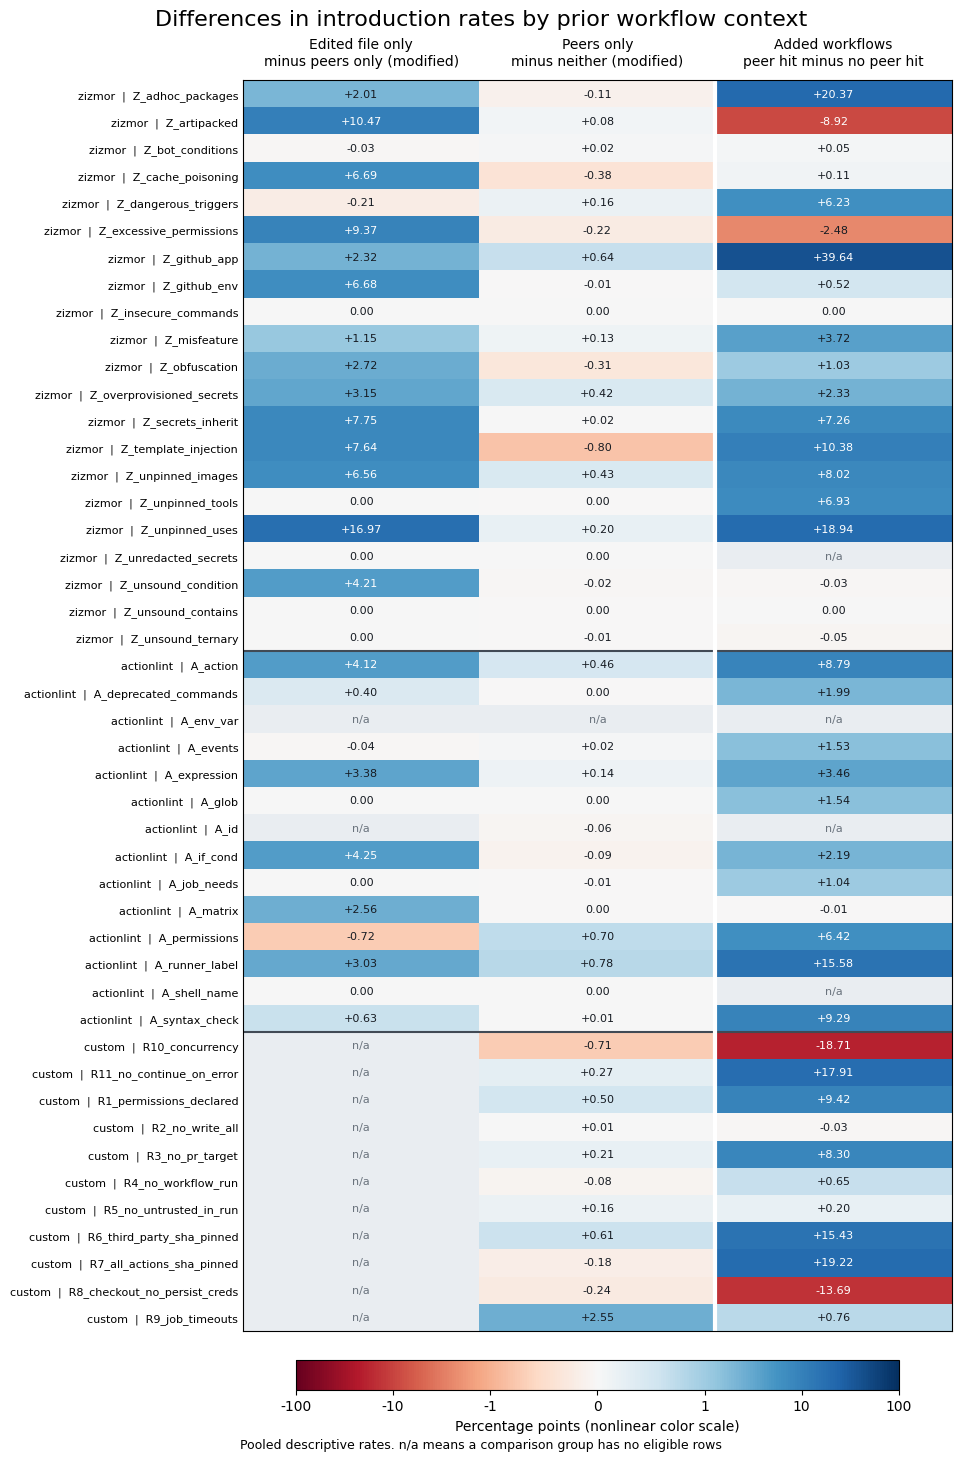

In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# Percentage-point differences use the original rates before rounding.
rates_by_group = rq2_rates_df.pivot(
    index=["oracle", "rule_id"],
    columns="context_group",
    values="introduction_rate_pct",
).reindex(index=rule_index, columns=context_order)

rq2_contrasts_df = pd.DataFrame({
    "Edited file only\nminus peers only (modified)": (
        rates_by_group["Edited file only"] - rates_by_group["Peers only"]
    ),
    "Peers only\nminus neither (modified)": (
        rates_by_group["Peers only"] - rates_by_group["Neither"]
    ),
    "Added workflows\npeer hit minus no peer hit": (
        rates_by_group["Added: peers had rule"]
        - rates_by_group["Added: no peer had rule"]
    ),
})

values = rq2_contrasts_df.to_numpy()
fig, ax = plt.subplots(figsize=(9.5, 14.5), layout="constrained")
cmap = plt.get_cmap("RdBu").with_extremes(bad="#e9edf1")
norm = SymLogNorm(linthresh=1, vmin=-100, vmax=100)
heatmap = ax.imshow(values, cmap=cmap, norm=norm, aspect="auto")

ax.set_xticks(range(len(rq2_contrasts_df.columns)), rq2_contrasts_df.columns)
ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False, length=0, pad=9)
ax.set_yticks(
    range(len(rq2_contrasts_df)),
    [f"{oracle}  |  {rule_id}" for oracle, rule_id in rq2_contrasts_df.index],
)
ax.tick_params(axis="y", length=0, labelsize=8)

row_labels = rq2_contrasts_df.index.get_level_values("oracle")
for row in range(1, len(row_labels)):
    if row_labels[row] != row_labels[row - 1]:
        ax.axhline(row - 0.5, color="#414a55", linewidth=1.5)
ax.axvline(1.5, color="white", linewidth=3)

for (row, column), difference in np.ndenumerate(values):
    if np.isnan(difference):
        label, color = "n/a", "#6a737d"
    else:
        label = f"{difference:+.2f}" if abs(difference) >= 0.005 else "0.00"
        red, green, blue, _ = cmap(norm(difference))
        luminance = 0.299 * red + 0.587 * green + 0.114 * blue
        color = "white" if luminance < 0.55 else "#161b22"
    ax.text(column, row, label, ha="center", va="center", fontsize=8, color=color)

fig.suptitle("Differences in introduction rates by prior workflow context", fontsize=16)
colorbar = fig.colorbar(
    heatmap, ax=ax, orientation="horizontal", shrink=0.85, pad=0.02,
    ticks=[-100, -10, -1, 0, 1, 10, 100], format="%g",
)
colorbar.set_label("Percentage points (nonlinear color scale)")
fig.supxlabel(
    "Pooled descriptive rates. n/a means a comparison group has no eligible rows",
    fontsize=9,
)

plot_path = paper_dir / "RQ2_context_contrasts.png"
fig.savefig(plot_path, dpi=200, facecolor="white")
plt.show()

### Introduction rates within repositories

Count introductions and eligible changes in each repository. For each comparison, use repositories with both groups. Compare their introduction rates and combine their differences in percentage points. Each repository's weight is `n_first * n_second / (n_first + n_second)`; both groups need observations for the repository to contribute. The pooled column uses all eligible changes and the within-repository column uses the shared repositories. These are descriptive estimates.

In [15]:
# Count eligible changes and introductions within each repository.
repo_by_pair = focal_pairs.set_index("pair_id")["repo"]
repo_count_tables = []

for (oracle, rule_id), rule_table in focal_rule_tables.items():
    eligible = rule_table.loc[rule_table["context_group"].ne("Unknown")]

    if oracle == "custom":
        eligible = eligible.loc[eligible["had_rule_before"].eq(False)]

    eligible = eligible.assign(repo=eligible.index.map(repo_by_pair))

    repo_counts = (
        eligible.groupby(["repo", "context_group"], observed=True)
        .agg(
            workflow_changes=("introduced_rule", "size"),
            changes_with_introduction=("introduced_rule", "sum"),
        )
        .reset_index()
    )
    repo_counts.insert(0, "rule_id", rule_id)
    repo_counts.insert(0, "oracle", oracle)
    repo_count_tables.append(repo_counts)

rq2_repo_counts_df = pd.concat(repo_count_tables, ignore_index=True)

# Verify that summing the repository counts reproduces the pooled counts.
group_keys = ["oracle", "rule_id", "context_group"]
count_columns = ["workflow_changes", "changes_with_introduction"]
recounted = (
    rq2_repo_counts_df.groupby(group_keys, observed=True)[count_columns]
    .sum()
    .sort_index()
)
expected = rq2_rates_df.set_index(group_keys)[count_columns].sort_index()
pd.testing.assert_frame_equal(recounted, expected, check_categorical=False)

print(f"{len(rq2_repo_counts_df):,} repository / rule / context rows")
display(rq2_repo_counts_df.head(10))

281,541 repository / rule / context rows


,oracle,rule_id,repo,context_group,workflow_changes,changes_with_introduction
0,actionlint,A_action,0101/pipetools,Both,1,0
1,actionlint,A_action,0phois/MudBlazor.StaticInput,Neither,2,0
2,actionlint,A_action,0x80/isolate-package,Added: no peer had rule,1,0
3,actionlint,A_action,0xMiden/protocol,Added: no peer had rule,2,0
4,actionlint,A_action,0xfurai/peekaping,Both,1,1
5,actionlint,A_action,0xfurai/peekaping,Peers only,2,0
6,actionlint,A_action,10000ge10000/luci-app-openclaw,Neither,1,0
7,actionlint,A_action,101t/jasmin-web-panel,Added: no peer had rule,1,0
8,actionlint,A_action,123jjck/cdn-ip-ranges,Neither,7,0
9,actionlint,A_action,14790897/auto-read-liunxdo,Added: peers had rule,1,0


In [16]:
comparisons = [
    ("Modified: edited file only vs. peers only", "Edited file only", "Peers only"),
    ("Modified: peers only vs. neither", "Peers only", "Neither"),
    ("Added: peer hit vs. no peer hit", "Added: peers had rule", "Added: no peer had rule"),
]

repo_wide = rq2_repo_counts_df.pivot(
    index=["oracle", "rule_id", "repo"],
    columns="context_group",
    values=["workflow_changes", "changes_with_introduction"],
)
pooled_rates = rq2_rates_df.pivot(
    index=["oracle", "rule_id"],
    columns="context_group",
    values="introduction_rate_pct",
)

repo_difference_tables = []
comparison_tables = []

for comparison, first, second in comparisons:
    n_first = repo_wide["workflow_changes"][first]
    n_second = repo_wide["workflow_changes"][second]

    # A repository contributes only if it has eligible changes in both groups.
    shared = n_first.gt(0) & n_second.gt(0)
    matched = pd.DataFrame({
        "n_first": n_first.loc[shared].astype(int),
        "n_second": n_second.loc[shared].astype(int),
        "events_first": repo_wide["changes_with_introduction"].loc[shared, first].astype(int),
        "events_second": repo_wide["changes_with_introduction"].loc[shared, second].astype(int),
    })
    matched["rate_first_pct"] = 100 * matched["events_first"] / matched["n_first"]
    matched["rate_second_pct"] = 100 * matched["events_second"] / matched["n_second"]
    matched["difference_pp"] = matched["rate_first_pct"] - matched["rate_second_pct"]

    # Reuse the repository fixed-effects weights from the earlier analysis.
    matched["weight"] = 1 / (1 / matched["n_first"] + 1 / matched["n_second"])
    matched["weighted_difference"] = matched["weight"] * matched["difference_pp"]
    matched["event_in_first"] = matched["events_first"].gt(0)
    matched["event_in_second"] = matched["events_second"].gt(0)

    results = matched.groupby(level=["oracle", "rule_id"]).agg(
        matched_repos=("difference_pp", "size"),
        event_repos_first=("event_in_first", "sum"),
        event_repos_second=("event_in_second", "sum"),
        matched_changes_first=("n_first", "sum"),
        matched_changes_second=("n_second", "sum"),
        total_weight=("weight", "sum"),
        weighted_difference=("weighted_difference", "sum"),
    )

    # Retain rules with no matched repositories so gaps are visible.
    results = results.reindex(pooled_rates.index)
    count_cols = [
        "matched_repos", "event_repos_first", "event_repos_second",
        "matched_changes_first", "matched_changes_second",
    ]
    results[count_cols] = results[count_cols].fillna(0).astype(int)
    results["within_repo_difference_pp"] = (
        results["weighted_difference"] / results["total_weight"]
    )
    results["pooled_difference_pp"] = pooled_rates[first] - pooled_rates[second]

    results = results.drop(columns=["total_weight", "weighted_difference"])
    results.insert(0, "comparison", comparison)
    matched.insert(0, "comparison", comparison)
    comparison_tables.append(results.reset_index())
    repo_difference_tables.append(matched.reset_index())

rq2_repo_diffs_df = pd.concat(repo_difference_tables, ignore_index=True)
rq2_within_repo_df = pd.concat(comparison_tables, ignore_index=True)

with pd.option_context("display.max_rows", None):
    display(rq2_within_repo_df.round(3))

,oracle,rule_id,comparison,matched_repos,event_repos_first,event_repos_second,matched_changes_first,matched_changes_second,within_repo_difference_pp,pooled_difference_pp
0,actionlint,A_action,Modified: edited file only vs. peers only,221,5,10,489,2780,0.287,4.122
1,actionlint,A_deprecated_commands,Modified: edited file only vs. peers only,71,1,0,228,1837,0.280,0.398
2,actionlint,A_env_var,Modified: edited file only vs. peers only,0,0,0,0,0,NaN,NaN
3,actionlint,A_events,Modified: edited file only vs. peers only,28,0,0,84,610,0.000,-0.041
4,actionlint,A_expression,Modified: edited file only vs. peers only,242,22,13,1014,102441,2.768,3.376
5,actionlint,A_glob,Modified: edited file only vs. peers only,17,0,0,32,446,0.000,0.000
6,actionlint,A_id,Modified: edited file only vs. peers only,0,0,0,0,0,NaN,NaN
7,actionlint,A_if_cond,Modified: edited file only vs. peers only,73,6,8,441,122023,4.091,4.253
8,actionlint,A_job_needs,Modified: edited file only vs. peers only,2,0,0,9,712,0.000,0.000
9,actionlint,A_matrix,Modified: edited file only vs. peers only,10,0,0,33,274,0.000,2.564


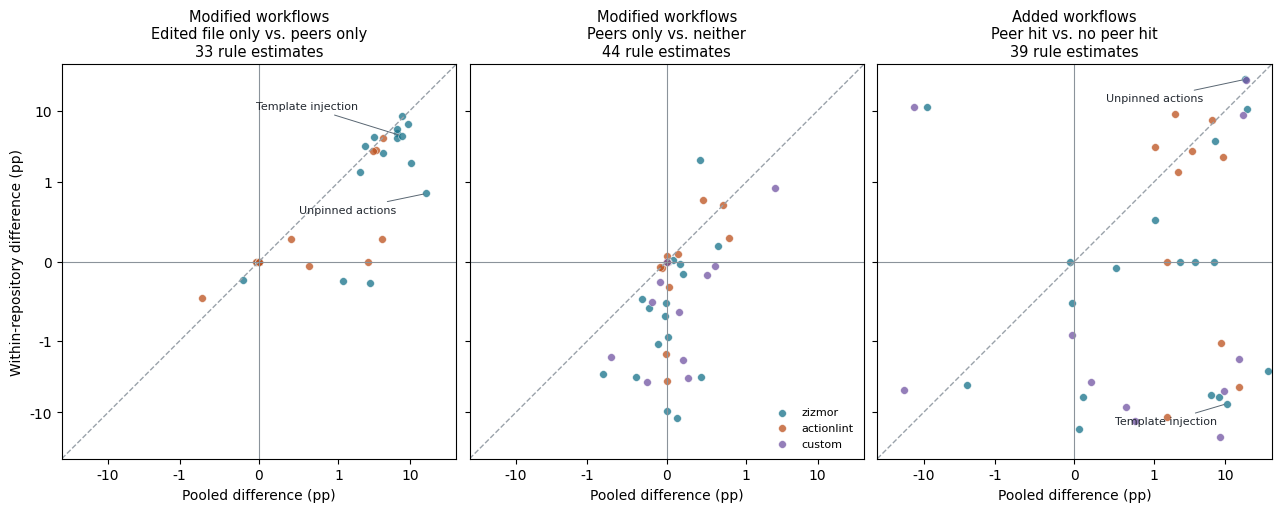

In [17]:
import matplotlib.pyplot as plt

plot_data = rq2_within_repo_df.dropna(
    subset=["pooled_difference_pp", "within_repo_difference_pp"]
)
panels = [
    ("Modified: edited file only vs. peers only", "Modified workflows\nEdited file only vs. peers only"),
    ("Modified: peers only vs. neither", "Modified workflows\nPeers only vs. neither"),
    ("Added: peer hit vs. no peer hit", "Added workflows\nPeer hit vs. no peer hit"),
]
colors = {"zizmor": "#18738a", "actionlint": "#bc521e", "custom": "#7355a3"}
labels = {
    0: {"Z_unpinned_uses": ("Unpinned actions", (-92, -14)),
        "Z_template_injection": ("Template injection", (-105, 19))},
    2: {"Z_unpinned_uses": ("Unpinned actions", (-100, -16)),
        "Z_template_injection": ("Template injection", (-80, -15))},
}

fig, axes = plt.subplots(1, 3, figsize=(12.7, 5.4), layout="constrained", sharey=True)
limit = 1.12 * plot_data[["pooled_difference_pp", "within_repo_difference_pp"]].abs().max().max()
ticks = [value for value in [-50, -10, -1, 0, 1, 10, 50] if abs(value) < limit]

for index, (ax, (comparison, title)) in enumerate(zip(axes, panels)):
    data = plot_data.loc[plot_data["comparison"].eq(comparison)]
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("symlog", linthresh=1)
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal")
    ax.set_xticks(ticks, [str(value) for value in ticks])
    ax.set_yticks(ticks, [str(value) for value in ticks])
    ax.axvline(0, color="#8b939b", linewidth=0.8)
    ax.axhline(0, color="#8b939b", linewidth=0.8)
    ax.plot([-limit, limit], [-limit, limit], "--", color="#9aa2aa", linewidth=1)
    for oracle, color in colors.items():
        points = data.loc[data["oracle"].eq(oracle)]
        ax.scatter(
            points["pooled_difference_pp"], points["within_repo_difference_pp"],
            s=31, color=color, alpha=0.76, edgecolor="white", linewidth=0.4, label=oracle,
        )
    for rule_id, (label, offset) in labels.get(index, {}).items():
        point = data.loc[data["rule_id"].eq(rule_id)].iloc[0]
        ax.annotate(
            label, (point["pooled_difference_pp"], point["within_repo_difference_pp"]),
            xytext=offset, textcoords="offset points", fontsize=8, color="#222830",
            arrowprops={"arrowstyle": "-", "color": "#596672", "linewidth": 0.7},
        )
    ax.set_title(f"{title}\n{len(data)} rule estimates", fontsize=10.5)
    ax.set_xlabel("Pooled difference (pp)")

axes[0].set_ylabel("Within-repository difference (pp)")
axes[1].legend(loc="lower right", fontsize=8, frameon=False)
# fig.suptitle("How introduction-rate differences change within repositories", fontsize=15)
# fig.supxlabel(
#     "One point per rule. Dashed line means equal estimates. Both axes expand the region near zero.",
#     fontsize=9,
# )
within_plot_path = paper_dir / "RQ2_pooled_vs_within_repository.png"
fig.savefig(within_plot_path, dpi=200, facecolor="white")
plt.show()

### Within-repository statistical check
Two-sided repository jackknife tests cover all estimable rules. Holm adjustment covers 127 planned contrasts, with unavailable tests counted as non-rejections. The old support threshold is retained as a filter. Intervals are pointwise.

In [18]:
from scipy.stats import t

# The custom checks use workflows that passed beforehand, so the
# edited-file-only comparison is unavailable for those rules.
tests = rq2_within_repo_df.loc[
    ~(
        rq2_within_repo_df["oracle"].eq("custom")
        & rq2_within_repo_df["comparison"].eq("Modified: edited file only vs. peers only")
    )
].copy()

# Retain the old support threshold as a descriptive flag.
tests["enough_support"] = (
    tests["matched_repos"].ge(10)
    & tests["event_repos_first"].ge(5)
    & tests["event_repos_second"].ge(5)
)

keys = ["oracle", "rule_id", "comparison"]
repo_groups = rq2_repo_diffs_df.groupby(keys, sort=False)
test_results = []

for row in tests.loc[tests["matched_repos"].ge(2)].itertuples(index=False):
    key = (row.oracle, row.rule_id, row.comparison)
    matched = repo_groups.get_group(key)
    n_repos = len(matched)
    if matched["difference_pp"].nunique() == 1:
        continue
    weights = matched["weight"]
    contributions = matched["weighted_difference"]

    # Recalculate the estimate after dropping each repository in turn.
    leave_one_out = (
        (contributions.sum() - contributions)
        / (weights.sum() - weights)
    )
    se = np.sqrt(
        (n_repos - 1) / n_repos
        * ((leave_one_out - leave_one_out.mean()) ** 2).sum()
    )
    if not np.isfinite(se) or se <= 0:
        continue

    effect = row.within_repo_difference_pp
    degrees_of_freedom = n_repos - 1
    margin = t.ppf(0.975, degrees_of_freedom) * se
    test_results.append({
        "oracle": row.oracle,
        "rule_id": row.rule_id,
        "comparison": row.comparison,
        "ci_low_pp": effect - margin,
        "ci_high_pp": effect + margin,
        "p_value": 2 * t.sf(abs(effect / se), degrees_of_freedom),
    })

test_columns = keys + ["ci_low_pp", "ci_high_pp", "p_value"]
rq2_tests_df = tests.merge(
    pd.DataFrame(test_results, columns=test_columns),
    on=keys, how="left", validate="one_to_one",
)

# Holm correction across the full set of applicable comparisons.
# Unavailable tests are counted as non-rejections in this correction.
ordered_p = rq2_tests_df["p_value"].fillna(1).sort_values()
multipliers = np.arange(len(ordered_p), 0, -1)
adjusted = (ordered_p * multipliers).cummax().clip(upper=1)
rq2_tests_df["p_holm"] = adjusted.where(rq2_tests_df["p_value"].notna())

rq2_tests_df["tested"] = rq2_tests_df["p_value"].notna()
rq2_tests_df["significant"] = rq2_tests_df["p_holm"].lt(0.05)

rq2_test_summary = (
    rq2_tests_df.groupby("comparison", sort=False)
    .agg(
        comparisons=("rule_id", "size"),
        tested=("tested", "sum"),
        significant=("significant", "sum"),
    )
)
display(rq2_test_summary)

show_columns = [
    "oracle", "rule_id", "comparison", "matched_repos",
    "within_repo_difference_pp", "ci_low_pp", "ci_high_pp", "p_value", "p_holm",
]
rq2_significant_df = (
    rq2_tests_df.loc[rq2_tests_df["significant"], show_columns]
    .sort_values("p_holm")
)
display(rq2_significant_df.round(4))

# Keep every applicable rule. Sort or filter only after Holm adjustment.
edited_peer_tests = rq2_tests_df.loc[
    rq2_tests_df["comparison"].eq("Modified: edited file only vs. peers only")
].copy()
edited_peer_tests["test_status"] = np.select(
    [edited_peer_tests["tested"], edited_peer_tests["matched_repos"].lt(2)],
    ["tested", "fewer than two shared repositories"],
    default="no estimable jackknife variance",
)
edited_peer_tests = edited_peer_tests.sort_values("p_holm", na_position="last")
edited_peer_tests.to_parquet(paper_dir / "RQ2_edited_vs_peers_tests.parquet", index=False)
display(edited_peer_tests[show_columns + ["enough_support", "test_status"]].round(4))

,comparisons,tested,significant
comparison,,,
Modified: edited file only vs. peers only,35,22,1
Modified: peers only vs. neither,46,37,2
Added: peer hit vs. no peer hit,46,34,0


,oracle,rule_id,comparison,matched_repos,within_repo_difference_pp,ci_low_pp,ci_high_pp,p_value,p_holm
17,zizmor,Z_cache_poisoning,Modified: edited file only vs. peers only,424,4.8414,3.0985,6.5842,0.0000,0.0000
63,zizmor,Z_cache_poisoning,Modified: peers only vs. neither,122,-3.1711,-4.7609,-1.5812,0.0001,0.0167
43,actionlint,A_job_needs,Modified: peers only vs. neither,6,-1.5245,-1.9159,-1.1331,0.0002,0.0212


,oracle,rule_id,comparison,matched_repos,within_repo_difference_pp,ci_low_pp,ci_high_pp,p_value,p_holm,enough_support,test_status
17,zizmor,Z_cache_poisoning,Modified: edited file only vs. peers only,424,4.8414,3.0985,6.5842,0.0000,0.0,True,tested
0,actionlint,A_action,Modified: edited file only vs. peers only,221,0.2866,-0.9802,1.5534,0.6561,1.0,True,tested
4,actionlint,A_expression,Modified: edited file only vs. peers only,242,2.7677,-0.8664,6.4018,0.1349,1.0,True,tested
1,actionlint,A_deprecated_commands,Modified: edited file only vs. peers only,71,0.2802,-0.3310,0.8914,0.3636,1.0,False,tested
10,actionlint,A_permissions,Modified: edited file only vs. peers only,5,-0.4620,-1.6204,0.6964,0.3303,1.0,False,tested
11,actionlint,A_runner_label,Modified: edited file only vs. peers only,146,2.7115,0.2932,5.1299,0.0282,1.0,True,tested
13,actionlint,A_syntax_check,Modified: edited file only vs. peers only,55,-0.0549,-0.1642,0.0544,0.3184,1.0,False,tested
7,actionlint,A_if_cond,Modified: edited file only vs. peers only,73,4.0908,-1.5589,9.7405,0.1532,1.0,True,tested
14,zizmor,Z_adhoc_packages,Modified: edited file only vs. peers only,208,1.3699,0.2602,2.4797,0.0158,1.0,True,tested
15,zizmor,Z_artipacked,Modified: edited file only vs. peers only,56,1.8605,-2.0798,5.8007,0.3482,1.0,False,tested


Experiment 2: textual proximity

Within an edited workflow, are newly flagged expression lines closer to surviving prior findings than comparable changed expression lines?

In [19]:
import numpy as np
import pandas as pd
from scipy.stats import t

proximity_df = pd.read_parquet(
    paper_dir / "RQ3 Line Proximity" / "run_field_matched.parquet"
)
assert proximity_df["pair_id"].is_unique

# Each edit contributes one paired difference, in lines.
proximity_df["difference_lines"] = (
    proximity_df["flagged_median_lines"] - proximity_df["control_median_lines"]
)

repo_totals = proximity_df.groupby("repo")["difference_lines"].agg(["sum", "size"])
n_repos = len(repo_totals)
n_edits = len(proximity_df)
total_difference = repo_totals["sum"].sum()
mean_difference = total_difference / n_edits

# Recompute the mean after leaving out all edits from each repository.
leave_one_out = (
    (total_difference - repo_totals["sum"]) / (n_edits - repo_totals["size"])
)
se = np.sqrt(
    (n_repos - 1) / n_repos
    * ((leave_one_out - leave_one_out.mean()) ** 2).sum()
)
margin = t.ppf(0.975, df=n_repos - 1) * se
p_value = 2 * t.sf(abs(mean_difference / se), df=n_repos - 1)

differences = proximity_df["difference_lines"]
textual_proximity_result = pd.DataFrame([{
    "workflow_edits": n_edits,
    "repos": n_repos,
    "closer": differences.lt(0).sum(),
    "tied": differences.eq(0).sum(),
    "farther": differences.gt(0).sum(),
    "median_difference_lines": differences.median(),
    "mean_difference_lines": mean_difference,
    "ci_low_lines": mean_difference - margin,
    "ci_high_lines": mean_difference + margin,
    "p_value": p_value,
}])
display(textual_proximity_result)

,workflow_edits,repos,closer,tied,farther,median_difference_lines,mean_difference_lines,ci_low_lines,ci_high_lines,p_value
0,370,123,233,5,132,-4.0,-19.232432,-31.42624,-7.038625,0.002241


### Proximity across rules

Use changed lines in the same type of YAML field as the newly flagged lines. Distances on both sides are to the nearest unchanged prior finding of that rule in that field type. The template-injection row retains the original shell-expression comparator. Show pointwise intervals for rules with at least 10 repositories and a nonzero standard error. Rules without eligible paired locations are shown as unavailable. These comparisons are exploratory.

In [ ]:
from IPython.display import Image

# Generated by RQ3 Line Proximity/all_rule_proximity.py.
all_rule_proximity_df = pd.read_parquet(
    paper_dir / "RQ3 Line Proximity" / "all_rule_proximity_summary.parquet"
)
# display(Image(filename=str(paper_dir / "RQ2_all_rule_proximity.png")))

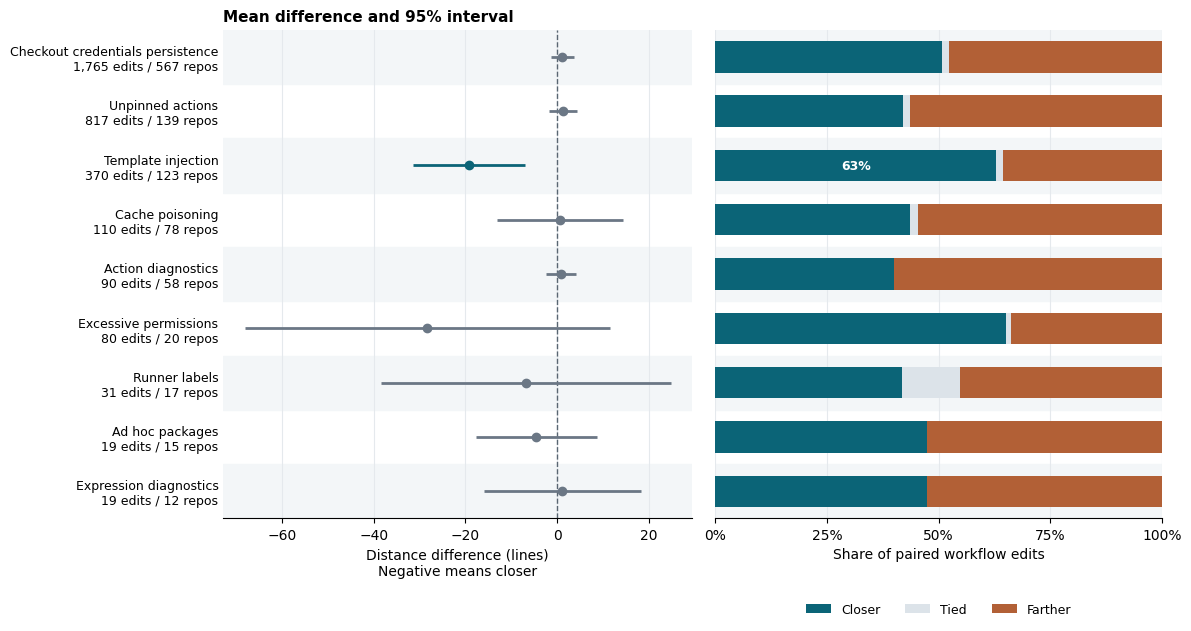

In [37]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

proximity_folder = paper_dir / "RQ3 Line Proximity"
proximity_summary = pd.read_parquet(proximity_folder / "all_rule_proximity_summary.parquet")
proximity_pairs = pd.read_parquet(proximity_folder / "all_rule_proximity_pairs.parquet")

# Focus the figure on rules with enough repository coverage for an interval.
shown = proximity_summary.loc[proximity_summary["ci_low_lines"].notna()].copy()

proximity_pairs["closer"] = proximity_pairs["difference_lines"].lt(0)
proximity_pairs["tied"] = proximity_pairs["difference_lines"].eq(0)
proximity_pairs["farther"] = proximity_pairs["difference_lines"].gt(0)
shares = proximity_pairs.groupby(["oracle", "rule_id"])[["closer", "tied", "farther"]].mean()
shown = shown.merge(shares, on=["oracle", "rule_id"], validate="one_to_one")
shown = shown.sort_values("matched_edits", ascending=False).reset_index(drop=True)

names = {
    "Z_artipacked": "Checkout credentials persistence",
    "Z_unpinned_uses": "Unpinned actions",
    "Z_template_injection": "Template injection",
    "Z_cache_poisoning": "Cache poisoning",
    "Z_excessive_permissions": "Excessive permissions",
    "Z_adhoc_packages": "Ad hoc packages",
    "A_action": "Action diagnostics",
    "A_runner_label": "Runner labels",
    "A_expression": "Expression diagnostics",
}
row_labels = [
    f"{names.get(row.rule_id, row.rule_id)}\n{row.matched_edits:,} edits / {row.matched_repos:,} repos"
    for row in shown.itertuples()
]

fig, (effect_ax, share_ax) = plt.subplots(
    1, 2, figsize=(11.8, 6.2), sharey=True, layout="constrained",
    gridspec_kw={"width_ratios": [1.05, 1]},
)
# fig.suptitle("Are newly flagged lines closer to prior findings?", fontsize=17, fontweight="bold")
for axis in (effect_ax, share_ax):
    axis.set_axisbelow(True)
    axis.grid(axis="x", color="#e5e9ed", linewidth=0.8)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.tick_params(axis="y", length=0)
    for i in range(0, len(shown), 2):
        axis.axhspan(i - 0.5, i + 0.5, color="#f3f6f8", zorder=0)
effect_ax.axvline(0, color="#596672", linestyle="--", linewidth=1)
effect_ax.set_yticks(shown.index, row_labels, fontsize=9)
effect_ax.set_ylim(len(shown) - 0.5, -0.5)
effect_ax.set_title("Mean difference and 95% interval", loc="left", fontsize=11, fontweight="bold")
effect_ax.set_xlabel("Distance difference (lines)\nNegative means closer")
for i, row in enumerate(shown.itertuples()):
    color = "#0b6477" if row.rule_id == "Z_template_injection" else "#6b7785"
    effect_ax.hlines(i, row.ci_low_lines, row.ci_high_lines, color=color, linewidth=2)
    effect_ax.scatter(row.mean_difference_lines, i, color=color, s=36, zorder=3)

left = np.zeros(len(shown))
for label, color in [("closer", "#0b6477"), ("tied", "#dce3e9"), ("farther", "#b26036")]:
    widths = shown[label].to_numpy()
    share_ax.barh(shown.index, widths, left=left, height=0.58, color=color, label=label.title())
    left += widths

template = shown.loc[shown["rule_id"].eq("Z_template_injection")].iloc[0]
share_ax.text(
    template["closer"] / 2, template.name, f"{template['closer']:.0%}",
    color="white", va="center", ha="center", fontsize=9, fontweight="bold",
)
share_ax.set_xlim(0, 1)
share_ax.set_xticks([0, 0.25, 0.50, 0.75, 1])
share_ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
# share_ax.set_title("How often were flagged lines closer?", loc="left", fontsize=11, fontweight="bold")
share_ax.set_xlabel("Share of paired workflow edits")
share_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=9)

# fig.supxlabel(
#     "Compares changed lines in the same YAML field type. Pointwise intervals account for clustering by repository.\n"
#     f"{len(shown)} of {len(proximity_summary)} screened rules shown. The full plot records coverage for every rule.",
#     fontsize=9,
# )
focused_proximity_plot = paper_dir / "RQ2_proximity_supported_rules.png"
fig.savefig(focused_proximity_plot, dpi=220, facecolor="white")
plt.show()

### Structural proximity for template injection

Use the same 370 workflow edits and compare each changed expression line to its nearest surviving prior finding. Calculate the share in the same step and the share in the same job for newly flagged lines and comparison lines in each edit. Average the paired differences across edits. Intervals use a repository jackknife, and Holm adjustment covers the two structural comparisons. The underlying pairs and summary come from template_injection_structure.py.

In [22]:
structural_proximity_df = pd.read_parquet(
    paper_dir / "RQ3 Line Proximity" / "template_injection_structural_summary.parquet"
)
display(structural_proximity_df.round(4))

,comparison,edits,repos,flagged_pct,control_pct,difference_pp,ci_low_pp,ci_high_pp,p_value,p_holm
0,Same step,370,123,8.2382,15.4388,-7.2007,-12.1625,-2.2388,0.0048,0.0096
1,Same job,370,123,66.9779,62.3527,4.6252,0.4874,8.7629,0.0288,0.0288


---

RQ3

RQ3: Does the association between pre-existing and newly introduced findings in modified workflows hold across coding agents and PR merge statuses?

### Does same-file recurrence hold across agents and merge outcomes?

Use the same 35 rules and modified workflows as RQ2. For each rule, compare the percentage of edits introducing an additional finding when the rule appeared only in the edited file versus only in peer workflows. Repeat the comparison once per agent, then separately once per resolved merge status. Each comparison uses repositories with edits on both sides for that subgroup.

In [25]:
rq3_meta = pd.read_parquet(
    outputs_dir / "pairs.parquet",
    columns=["pair_id", "agent_name", "state", "merged_at"],
    filters=[("source", "==", "aidev_v5")],
).set_index("pair_id", verify_integrity=True)

rq3_meta["merge_status"] = np.select(
    [rq3_meta["merged_at"].notna(), rq3_meta["state"].eq("closed"), rq3_meta["state"].eq("open")],
    ["Merged", "Closed without merge", "Open"],
    default="Unknown",
)
rq3_meta["repo"] = focal_pairs.set_index("pair_id")["repo"]

In [26]:
contexts = ["Edited file only", "Peers only"]
dimensions = ["agent_name", "merge_status"]
counts_by_group = []

for (oracle, rule), table in focal_rule_tables.items():
    if oracle not in ["zizmor", "actionlint"]:
        continue

    edits = table.loc[table["context_group"].isin(contexts), ["context_group", "introduced_rule"]]
    edits = edits.join(rq3_meta, validate="one_to_one")
    assert edits[["repo", *dimensions]].notna().all().all()

    for dimension in dimensions:
        counts = edits.groupby([dimension, "repo", "context_group"], observed=True).agg(
            edits=("introduced_rule", "size"),
            introductions=("introduced_rule", "sum"),
        ).reset_index()
        assert counts["edits"].sum() == len(edits)
        counts = counts.rename(columns={dimension: "subgroup"})
        counts_by_group.append(counts.assign(oracle=oracle, rule_id=rule, dimension=dimension))

rq3_counts = pd.concat(counts_by_group, ignore_index=True)
# Coverage counts workflow-edit/rule combinations. One edit can contribute to several rules.
display(rq3_counts.groupby(["dimension", "subgroup"])[["edits", "introductions"]].sum())

edits  introductions
dimension    subgroup                                    
agent_name   Claude_Code             13843            174
             Copilot               1298571           3053
             Cursor                  17737            158
             Devin                   23652            294
             Google_Jules             2915             18
             OpenAI_Codex            34177            699
merge_status Closed without merge   292109           1230
             Merged                1062677           2719
             Open                    36109            447

In [27]:
from scipy.stats import t

def subgroup_result(counts):
    sizes = counts.pivot(index="repo", columns="context_group", values="edits").reindex(columns=contexts).fillna(0)
    events = counts.pivot(index="repo", columns="context_group", values="introductions").reindex(columns=contexts).fillna(0)
    pooled = 100 * events.sum() / sizes.sum().replace(0, np.nan)

    shared = sizes.gt(0).all(axis=1)
    sizes, events = sizes.loc[shared], events.loc[shared]
    n = len(sizes)
    result = dict(
        matched_repos=n, file_edits=sizes.iloc[:, 0].sum(), peer_edits=sizes.iloc[:, 1].sum(),
        file_event_repos=events.iloc[:, 0].gt(0).sum(), peer_event_repos=events.iloc[:, 1].gt(0).sum(),
        pooled_pp=pooled.iloc[0] - pooled.iloc[1], within_pp=np.nan,
        ci_low=np.nan, ci_high=np.nan, p_value=np.nan,
    )
    if n == 0:
        return result

    rates = 100 * events / sizes
    gaps = rates.iloc[:, 0] - rates.iloc[:, 1]
    weights = 1 / (1 / sizes.iloc[:, 0] + 1 / sizes.iloc[:, 1])
    contributions = weights * gaps
    effect = contributions.sum() / weights.sum()
    result["within_pp"] = effect
    if n < 2 or gaps.nunique() == 1:
        return result

    # Drop one whole repository at a time, as in RQ2.
    leave_one_out = (contributions.sum() - contributions) / (weights.sum() - weights)
    se = np.sqrt((n - 1) / n * ((leave_one_out - leave_one_out.mean()) ** 2).sum())
    if np.isfinite(se) and se > 0:
        margin = t.ppf(0.975, n - 1) * se
        result.update(ci_low=effect-margin, ci_high=effect+margin, p_value=2*t.sf(abs(effect/se), n-1))
    return result

In [28]:
rows = []
rules_to_compare = [(o, r) for o, r in focal_rule_tables if o in ["zizmor", "actionlint"]]
for oracle, rule in rules_to_compare:
    rule_counts = rq3_counts.loc[rq3_counts["rule_id"].eq(rule) & rq3_counts["oracle"].eq(oracle)]
    for dimension in dimensions:
        groups = sorted(rq3_meta["agent_name"].dropna().unique()) if dimension == "agent_name" else ["Merged", "Closed without merge"]
        for subgroup in groups:
            counts = rule_counts.loc[rule_counts["dimension"].eq(dimension) & rule_counts["subgroup"].eq(subgroup)]
            rows.append(dict(oracle=oracle, rule_id=rule, dimension=dimension, subgroup=subgroup, **subgroup_result(counts)))

rq3_results = pd.DataFrame(rows)
# Adjust once across all planned RQ3 subgroup tests before filtering.
ordered = rq3_results["p_value"].fillna(1).sort_values()
adjusted = (ordered * np.arange(len(ordered), 0, -1)).cummax().clip(upper=1)
rq3_results["p_holm"] = adjusted.where(rq3_results["p_value"].notna())
reference = rq2_within_repo_df.loc[
    rq2_within_repo_df["comparison"].eq("Modified: edited file only vs. peers only"),
    ["oracle", "rule_id", "within_repo_difference_pp"],
].rename(columns={"within_repo_difference_pp": "rq2_overall_pp"})
rq3_results = rq3_results.merge(reference, on=["oracle", "rule_id"], validate="many_to_one")
rq3_results.to_parquet(paper_dir / "RQ3_agent_and_merge_results.parquet", index=False)

# Start with the rule highlighted in RQ2. Change rule_id to inspect another.
rule_id = "Z_cache_poisoning"
display(rq3_results.loc[rq3_results["rule_id"].eq(rule_id)].round(4))

,oracle,rule_id,dimension,subgroup,matched_repos,file_edits,peer_edits,file_event_repos,peer_event_repos,pooled_pp,within_pp,ci_low,ci_high,p_value,p_holm,rq2_overall_pp
136,zizmor,Z_cache_poisoning,agent_name,Claude_Code,53,78.0,401.0,6,0,7.4204,7.0201,1.1037,12.9366,0.0210,1.0000,4.8414
137,zizmor,Z_cache_poisoning,agent_name,Copilot,224,675.0,153178.0,19,10,6.1426,4.3427,1.7826,6.9029,0.0010,0.2694,4.8414
138,zizmor,Z_cache_poisoning,agent_name,Cursor,26,92.0,864.0,5,0,6.6473,5.1651,-3.0258,13.3561,0.2059,1.0000,4.8414
139,zizmor,Z_cache_poisoning,agent_name,Devin,9,14.0,66.0,1,0,15.8786,13.6965,-17.7364,45.1294,0.3444,1.0000,4.8414
140,zizmor,Z_cache_poisoning,agent_name,Google_Jules,7,27.0,829.0,1,0,2.7027,3.0493,-13.8766,19.9753,0.6748,1.0000,4.8414
141,zizmor,Z_cache_poisoning,agent_name,OpenAI_Codex,131,363.0,1393.0,17,3,7.1086,5.1516,1.8712,8.4320,0.0023,0.6409,4.8414
142,zizmor,Z_cache_poisoning,merge_status,Merged,312,797.0,120937.0,29,8,6.0978,4.3085,2.5090,6.1080,0.0000,0.0010,4.8414
143,zizmor,Z_cache_poisoning,merge_status,Closed without merge,136,252.0,34345.0,16,4,9.0380,7.0632,3.0859,11.0406,0.0006,0.1682,4.8414


In [29]:
rq3_results

,oracle,rule_id,dimension,subgroup,matched_repos,file_edits,peer_edits,file_event_repos,peer_event_repos,pooled_pp,within_pp,ci_low,ci_high,p_value,p_holm,rq2_overall_pp
0,actionlint,A_action,agent_name,Claude_Code,22,36.0,167.0,0,0,4.317876,0.000000,NaN,NaN,NaN,NaN,0.286588
1,actionlint,A_action,agent_name,Copilot,123,264.0,1669.0,2,5,4.714345,0.019623,-1.634383,1.673628,0.981302,1.0,0.286588
2,actionlint,A_action,agent_name,Cursor,14,30.0,52.0,1,0,3.319458,4.661142,-5.766086,15.088371,0.351807,1.0,0.286588
3,actionlint,A_action,agent_name,Devin,5,21.0,60.0,0,0,-0.063816,0.000000,NaN,NaN,NaN,NaN,0.286588
4,actionlint,A_action,agent_name,Google_Jules,2,4.0,28.0,0,0,22.222222,0.000000,NaN,NaN,NaN,NaN,0.286588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
275,zizmor,Z_unsound_ternary,agent_name,Devin,0,0.0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
276,zizmor,Z_unsound_ternary,agent_name,Google_Jules,0,0.0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
277,zizmor,Z_unsound_ternary,agent_name,OpenAI_Codex,3,4.0,58.0,0,0,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000
278,zizmor,Z_unsound_ternary,merge_status,Merged,9,21.0,219.0,0,0,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000


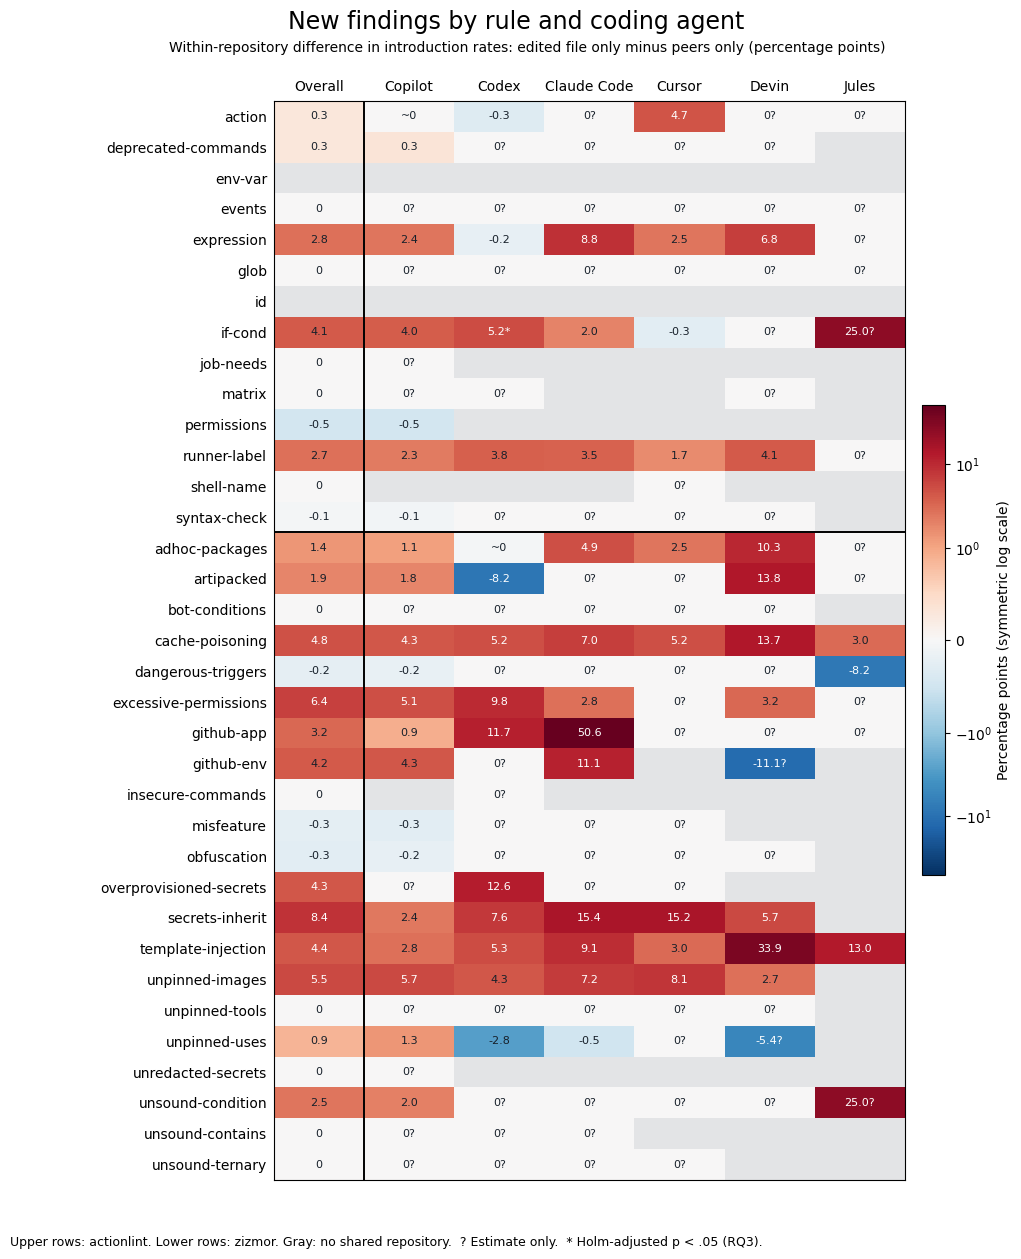

In [31]:
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# One row per rule. The overall column gives the RQ2 reference for each row.
by_agent = rq3_results.loc[rq3_results["dimension"].eq("agent_name")]
agent_order = ["Copilot", "OpenAI_Codex", "Claude_Code", "Cursor", "Devin", "Google_Jules"]
effects = by_agent.pivot(index=["oracle", "rule_id"], columns="subgroup", values="within_pp")[agent_order]
effects.insert(0, "Overall", by_agent.groupby(["oracle", "rule_id"])["rq2_overall_pp"].first())
effects = effects.sort_index()
agent_tests = by_agent.set_index(["oracle", "rule_id", "subgroup"])

fig, ax = plt.subplots(figsize=(11, 13))
fig.subplots_adjust(left=.28, right=.89, top=.90, bottom=.07)
colors = plt.get_cmap("RdBu_r").copy()
colors.set_bad("#e3e4e6")
limit = max(1, effects.abs().max().max())
scale = SymLogNorm(linthresh=1, vmin=-limit, vmax=limit)
heat = ax.imshow(effects, cmap=colors, norm=scale, aspect="auto")

for y, (oracle, rule) in enumerate(effects.index):
    for x, group in enumerate(effects.columns):
        value = effects.loc[(oracle, rule), group]
        if pd.isna(value):
            continue
        label = f"{value:.1f}" if abs(value) >= .05 else ("0" if value == 0 else "~0")
        if group != "Overall":
            row = agent_tests.loc[(oracle, rule, group)]
            if row.p_holm < .05:
                label += "*"
            elif pd.isna(row.p_value):
                label += "?"
        color = "white" if abs(scale(value) - .5) > .31 else "#17202a"
        ax.text(x, y, label, ha="center", va="center", color=color, fontsize=8)

ax.set_xticks(range(len(effects.columns)), ["Overall", "Copilot", "Codex", "Claude Code", "Cursor", "Devin", "Jules"])
ax.xaxis.tick_top()
ax.set_yticks(range(len(effects)), [rule[2:].replace("_", "-") for _, rule in effects.index])
ax.tick_params(length=0, pad=5)
ax.axvline(.5, color="black", linewidth=1.4)
boundary = sum(effects.index.get_level_values("oracle") == "actionlint")
ax.axhline(boundary-.5, color="black", linewidth=1.4)
fig.suptitle("New findings by rule and coding agent", fontsize=17, y=.97)
fig.text(.51,.938,"Within-repository difference in introduction rates: edited file only minus peers only (percentage points)", ha="center", fontsize=10)
fig.colorbar(heat, ax=ax, fraction=.035, pad=.025, label="Percentage points (symmetric log scale)")
fig.text(.04,.019,"Upper rows: actionlint. Lower rows: zizmor. Gray: no shared repository.  ? Estimate only.  * Holm-adjusted p < .05 (RQ3).", fontsize=9)
fig.savefig(paper_dir / "RQ3_all_rules_by_agent.png", dpi=200, bbox_inches="tight")
plt.show()

subgroup                            Claude_Code  Copilot  Cursor  Devin  Google_Jules  OpenAI_Codex
oracle     rule_id                                                                                 
zizmor     Z_cache_poisoning               7.02     4.34    5.17  13.70          3.05          5.15
           Z_template_injection            9.09     2.80    3.03  33.89         13.04          5.34
actionlint A_expression                    8.79     2.44    2.48   6.80          0.00         -0.21
zizmor     Z_excessive_permissions         2.75     5.10    0.00   3.19          0.00          9.80
actionlint A_action                        0.00     0.02    4.66   0.00          0.00         -0.34
zizmor     Z_adhoc_packages                4.94     1.12    2.49  10.33          0.00         -0.05
           Z_dangerous_triggers            0.00    -0.18    0.00   0.00         -8.18          0.00
actionlint A_runner_label                  3.51     2.29    1.67   4.05          0.00          3.80


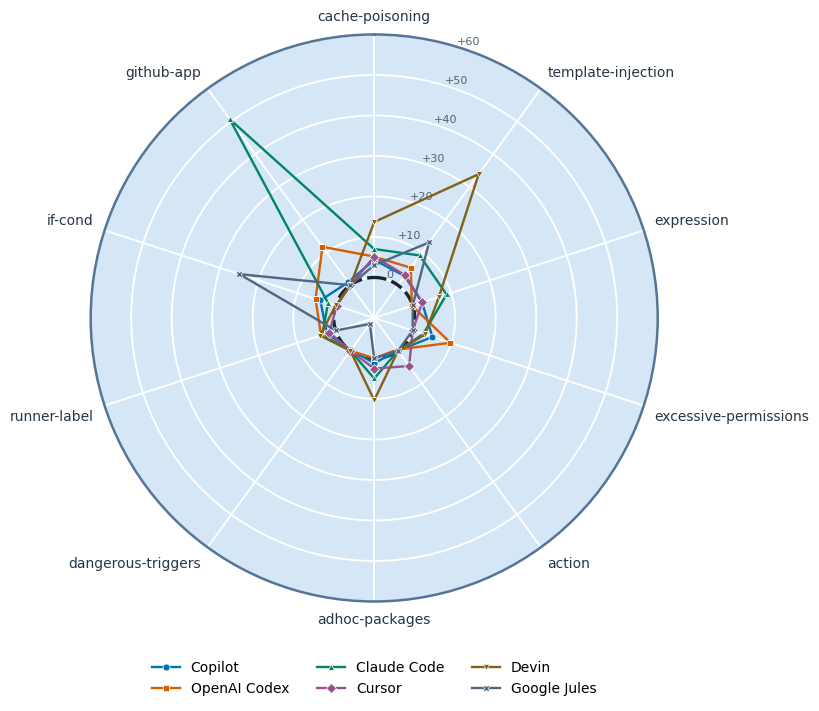

In [33]:
# Rank by the number of agents with a within-repo estimate, then by matched repo counts.
agent_rows = rq3_results.loc[rq3_results["dimension"].eq("agent_name")]
support = agent_rows.groupby(["oracle", "rule_id"]).agg(
    agents_with_estimate=("within_pp", "count"), agent_repo_matches=("matched_repos", "sum")
)
top_rules = support.sort_values(["agents_with_estimate", "agent_repo_matches"], ascending=False).head(10)
gaps = agent_rows.pivot(index=["oracle", "rule_id"], columns="subgroup", values="within_pp").loc[top_rules.index]
print(gaps.round(2).to_string())


# Use a linear scale. A gap of zero lies on the bold ring.
angles = np.linspace(0, 2*np.pi, len(gaps), endpoint=False)
lower = 10 * np.floor(min(0, gaps.min().min()) / 10)
upper = 10 * np.ceil(max(0, gaps.max().max()) / 10)
fig = plt.figure(figsize=(10, 9), facecolor="white")
ax = fig.add_axes([.16, .18, .68, .63], projection="polar")
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, upper - lower)
ax.spines["polar"].set_color("#547597")
ax.spines["polar"].set_linewidth(1.8)
ax.set_axisbelow(True)
ax.set_facecolor("#d5e6f7")
ax.grid(color="white", linewidth=1.35)
ax.set_xticks(angles)
ax.tick_params(axis="x", labelbottom=False)
labels = [rule[2:].replace("_", "-") for _, rule in gaps.index]
spoke_labels = []
for angle, label in zip(angles, labels):
    x_direction, y_direction = np.sin(angle), np.cos(angle)
    horizontal = "left" if x_direction > .1 else "right" if x_direction < -.1 else "center"
    vertical = "bottom" if y_direction > .1 else "top" if y_direction < -.1 else "center"
    spoke_labels.append(ax.annotate(
        label, (angle, upper - lower),
        xytext=(8 * x_direction, 8 * y_direction), textcoords="offset points",
        ha=horizontal, va=vertical, fontsize=10, color="#253647",
        annotation_clip=False,
    ))
ticks = np.arange(lower + 10, upper + 1, 10)
ax.set_yticks(ticks - lower, ["0" if v == 0 else f"{v:+.0f}" for v in ticks],
              fontsize=8, color="#51616b")
ax.set_rlabel_position(17)
circle = np.linspace(0, 2*np.pi, 361)
ax.plot(circle, np.full_like(circle, -lower), color="#172532", lw=2.4, linestyle="--", zorder=2)
styles = [
    ("Copilot", "#0072b2", "o"), ("OpenAI_Codex", "#d55e00", "s"),
    ("Claude_Code", "#008566", "^"), ("Cursor", "#98528d", "D"),
    ("Devin", "#826115", "v"), ("Google_Jules", "#506682", "X"),
]
for agent, color, marker in styles:
    radii = gaps[agent].to_numpy() - lower
    ax.plot(np.r_[angles, angles[0]], np.r_[radii, radii[0]], color=color,
            marker=marker, lw=1.7, ms=5, markeredgecolor="white", markeredgewidth=.5,
            label=agent.replace("_", " "))

# fig.text(.5, .955, "Do Findings Recur More Often in Edited Workflows?",
#          ha="center", fontsize=19, fontweight="bold", color="#1c3040")
# fig.text(.5, .915, "Within-repository rate difference by coding agent, in percentage points",
#          ha="center", fontsize=11, color="#455765")
ax.legend(loc="center", bbox_to_anchor=(.5, .095), bbox_transform=fig.transFigure,
          ncol=3, frameon=False, columnspacing=2, fontsize=10)
# fig.text(.5, .038, "Dashed inner ring marks 0 pp. Results outside it indicate introductions were more frequent in edited-file-only cases.",
        #  ha="center", fontsize=10, color="#455765")
fig.savefig(paper_dir / "RQ3_top10_within_repo_by_agent.png", dpi=220, bbox_inches="tight", pad_inches=.25, facecolor=fig.get_facecolor())
plt.show()


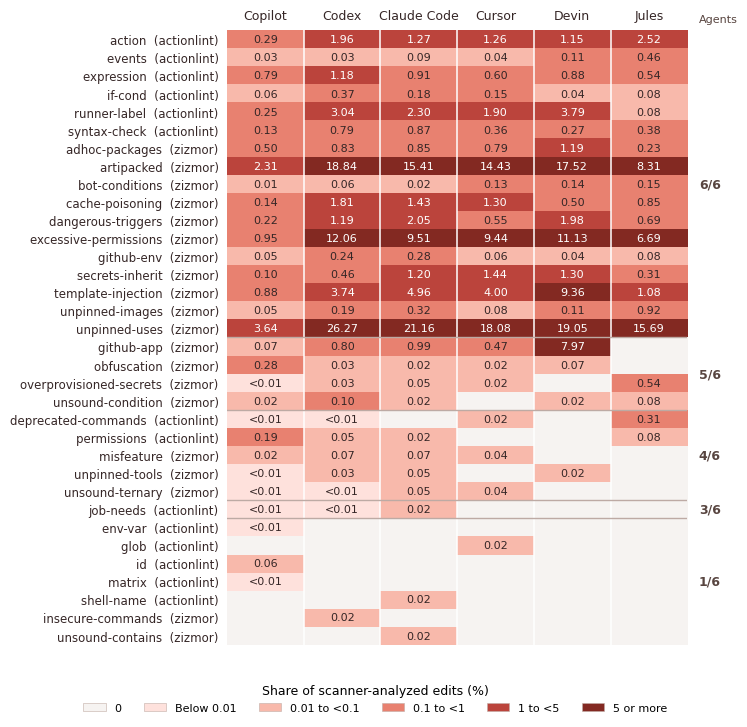

In [36]:
import json
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

scanners = ["actionlint", "zizmor"]
aidev_filter = [("source", "==", "aidev_v5")]
edits = pd.read_parquet(full_run_dir / "pairs_summary.parquet",
                        columns=["pair_id", "agent_name", "scan_status"],
                        filters=aidev_filter)
statuses = pd.DataFrame(edits["scan_status"].map(json.loads).tolist(), index=edits.index)
analyzed = edits[["pair_id", "agent_name"]].join(statuses[scanners].eq("analyzed"))
analyzed = analyzed.melt(id_vars=["pair_id", "agent_name"], var_name="oracle", value_name="analyzed")
analyzed = analyzed.loc[analyzed["analyzed"] & analyzed["agent_name"].notna()]
denominators = analyzed.groupby(["oracle", "agent_name"]).size().unstack()

findings = pd.read_parquet(full_run_dir / "findings.parquet",
                           columns=["pair_id", "oracle", "rule_id"],
                           filters=aidev_filter + [("status", "==", "introduced"),
                                                   ("oracle", "in", scanners)]).drop_duplicates()
rule_keys = rq3_results[["oracle", "rule_id"]].drop_duplicates()
findings = findings.merge(rule_keys, on=["oracle", "rule_id"], validate="many_to_one")
findings = findings.merge(analyzed[["pair_id", "oracle", "agent_name"]],
                          on=["pair_id", "oracle"], validate="many_to_one")

agents = ["Copilot", "OpenAI_Codex", "Claude_Code", "Cursor", "Devin", "Google_Jules"]
counts = (findings.groupby(["oracle", "rule_id", "agent_name"]).size()
          .unstack(fill_value=0).reindex(columns=agents, fill_value=0))
breadth = counts.gt(0).sum(axis=1).sort_values(ascending=False, kind="stable")
counts = counts.loc[breadth.index]
eligible = denominators.reindex(counts.index.get_level_values("oracle"))[agents]
eligible.index = counts.index
agent_rule_rates = 100 * counts / eligible


# Use labeled rate bands for color and print the measured rate in each occupied cell.
rates = agent_rule_rates.to_numpy()
bands = np.digitize(rates, [.01, .1, 1, 5]) + 1
bands[rates == 0] = 0
palette = ["#f6f3f1", "#fee1dc", "#f8b9ab", "#e88170", "#bb443c", "#832922"]
colors = ListedColormap(palette)

fig, ax = plt.subplots(figsize=(7.8, 8.3), facecolor="white")
fig.subplots_adjust(left=.31, right=.90, top=.86, bottom=.12)
ax.imshow(bands, aspect="auto", cmap=colors, vmin=0, vmax=5, interpolation="nearest")
ax.vlines(np.arange(.5, len(agents) - 1, 1), -.5, len(counts) - .5, color="white", linewidth=1.1)

for y, row in enumerate(rates):
    for x, rate in enumerate(row):
        if rate == 0:
            continue
        label = f"{rate:.2f}" if rate >= .01 else "<0.01"
        ax.text(x, y, label, ha="center", va="center", fontsize=8,
                color="white" if bands[y, x] >= 4 else "#352626")

# Group rules by the number of agents with a positive rate.
for number, block in breadth.groupby(breadth, sort=False):
    positions = np.flatnonzero(breadth.to_numpy() == number)
    ax.text(len(agents) - .35, positions.mean(), f"{number}/6", va="center",
            fontsize=9, color="#584540", fontweight="bold", clip_on=False)
    if positions[-1] < len(counts) - 1:
        ax.axhline(positions[-1] + .5, color="#bdaaa4", linewidth=1)
ax.text(len(agents) - .35, -.98, "Agents", fontsize=8, color="#584540", clip_on=False)
ax.set_yticks(range(len(counts)), [f"{rule[2:].replace('_', '-')}  ({scanner})"
                                 for scanner, rule in counts.index], fontsize=8.5)
ax.set_xticks(range(len(agents)), ["Copilot", "Codex", "Claude Code", "Cursor", "Devin", "Jules"],
              fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(length=0, pad=6, colors="#352626")
ax.spines[:].set_visible(False)

# fig.text(.04, .966, "Introduced Workflow Findings Across Agents",
#          fontsize=16, fontweight="bold", color="#352626")
# fig.text(.04, .933, f"{breadth.eq(6).sum()} of {len(breadth)} rules appeared across all six agents.",
#          fontsize=10, color="#584540")
legend_labels = ["0", "Below 0.01", "0.01 to <0.1", "0.1 to <1", "1 to <5", "5 or more"]
legend = [Patch(facecolor=color, edgecolor="#c1ada6", linewidth=.4, label=label)
          for color, label in zip(palette, legend_labels)]
fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(.5, .026),
           ncol=6, frameon=False, fontsize=8, title="Share of scanner-analyzed edits (%)",
           title_fontsize=9)
fig.savefig(paper_dir / "RQ3_agent_by_rule_rates.png", dpi=240, bbox_inches="tight", pad_inches=.15)
plt.show()
